In [1]:
# Mount Google Drive so the original dataset, models, and results remain accessible.
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
# Import the libraries required for data preparation, transfer learning, and evaluation.
import os
import shutil
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

print("TensorFlow version:", tf.__version__)
print("Available GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# Define Drive and local paths, then copy the dataset to Colab storage if needed.
PROJECT_DIR = "/content/drive/MyDrive/Brain_Tumor_CNN_Project"
DRIVE_DATASET_DIR = os.path.join(
    PROJECT_DIR, "dataset", "Epic and CSCR hospital Dataset"
)
LOCAL_DATASET_DIR = "/content/brain_tumor_dataset"
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

if not os.path.isdir(DRIVE_DATASET_DIR):
    raise FileNotFoundError(f"Dataset not found in Drive: {DRIVE_DATASET_DIR}")

if not os.path.isdir(LOCAL_DATASET_DIR):
    print("Copying dataset to Colab local storage...")
    shutil.copytree(DRIVE_DATASET_DIR, LOCAL_DATASET_DIR)
    print("Dataset copy complete.")
else:
    print("Local dataset copy already exists; reusing it.")

DATASET_DIR = LOCAL_DATASET_DIR
TRAIN_DIR = os.path.join(DATASET_DIR, "Train")
TEST_DIR = os.path.join(DATASET_DIR, "Test")

print("Local dataset:", DATASET_DIR)
print("Train folder exists:", os.path.isdir(TRAIN_DIR))
print("Test folder exists:", os.path.isdir(TEST_DIR))
print("Model output folder:", MODEL_DIR)
print("Results folder:", RESULTS_DIR)

Copying dataset to Colab local storage...
Dataset copy complete.
Local dataset: /content/brain_tumor_dataset
Train folder exists: True
Test folder exists: True
Model output folder: /content/drive/MyDrive/Brain_Tumor_CNN_Project/models
Results folder: /content/drive/MyDrive/Brain_Tumor_CNN_Project/results


In [4]:
# Define the binary label mapping and collect images in a deterministic sorted order.
CLASS_MAPPING = {
    "notumor": 0,
    "glioma": 1,
    "meningioma": 1,
    "pituitary": 1
}
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".jfif")

def collect_images(split_dir):
    rows = []
    for class_name, label in CLASS_MAPPING.items():
        class_dir = os.path.join(split_dir, class_name)
        if not os.path.isdir(class_dir):
            raise FileNotFoundError(f"Missing class directory: {class_dir}")

        for filename in sorted(os.listdir(class_dir)):
            if filename.lower().endswith(IMAGE_EXTENSIONS):
                image_path = os.path.join(class_dir, filename)
                if os.path.isfile(image_path):
                    rows.append({
                        "image_path": image_path,
                        "original_class": class_name,
                        "label": label
                    })
    return pd.DataFrame(rows)

all_train_df = collect_images(TRAIN_DIR)
test_df = collect_images(TEST_DIR)

print("Training pool images:", len(all_train_df))
print("Independent test images:", len(test_df))
print("Training pool labels (0=Non-Tumour, 1=Tumour):")
print(all_train_df["label"].value_counts().sort_index())
print("Test labels:")
print(test_df["label"].value_counts().sort_index())

Training pool images: 9650
Independent test images: 2415
Training pool labels (0=Non-Tumour, 1=Tumour):
label
0    1945
1    7705
Name: count, dtype: int64
Test labels:
label
0     487
1    1928
Name: count, dtype: int64


In [5]:
# Create a stratified training/validation split and save the exact split paths for reproducibility.
train_df, val_df = train_test_split(
    all_train_df,
    test_size=0.20,
    stratify=all_train_df["label"],
    random_state=42
)

train_df = train_df.sort_values(["label", "image_path"]).reset_index(drop=True)
val_df = val_df.sort_values(["label", "image_path"]).reset_index(drop=True)
test_df = test_df.sort_values(["label", "image_path"]).reset_index(drop=True)

train_df.to_csv(os.path.join(RESULTS_DIR, "efficientnet_train_split.csv"), index=False)
val_df.to_csv(os.path.join(RESULTS_DIR, "efficientnet_validation_split.csv"), index=False)
test_df.to_csv(os.path.join(RESULTS_DIR, "efficientnet_test_manifest.csv"), index=False)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Training distribution:\n", train_df["label"].value_counts().sort_index())
print("Validation distribution:\n", val_df["label"].value_counts().sort_index())

Training images: 7720
Validation images: 1930
Test images: 2415
Training distribution:
 label
0    1556
1    6164
Name: count, dtype: int64
Validation distribution:
 label
0     389
1    1541
Name: count, dtype: int64


In [6]:
# Define image resizing and decoding; EfficientNetB0 includes its own input rescaling.
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

def preprocess_image(image_path, label):
    image_bytes = tf.io.read_file(image_path)
    image = tf.io.decode_image(
        image_bytes, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)  # Keep 0–255 scale for Keras EfficientNetB0.
    label = tf.cast(label, tf.float32)
    return image, label

print("Image preprocessing function ready.")

Image preprocessing function ready.


In [7]:
# Build optimized TensorFlow datasets with parallel mapping and prefetching for faster training.
def create_dataset(df, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (df["image_path"].values, df["label"].values.astype("float32"))
    )
    dataset = dataset.map(
        preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=min(len(df), 4000),
            seed=SEED,
            reshuffle_each_iteration=True
        )
    dataset = dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return dataset

train_dataset = create_dataset(train_df, shuffle=True)
val_dataset = create_dataset(val_df)
test_dataset = create_dataset(test_df)

print("Train batches:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_dataset).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_dataset).numpy())

Train batches: 242
Validation batches: 61
Test batches: 76


In [8]:
# Verify image tensor dimensions and pixel scale before training.
images_batch, labels_batch = next(iter(train_dataset))
print("Image batch shape:", images_batch.shape)
print("Label batch shape:", labels_batch.shape)
print("Pixel minimum:", float(tf.reduce_min(images_batch).numpy()))
print("Pixel maximum:", float(tf.reduce_max(images_batch).numpy()))
print("Sample labels:", labels_batch[:10].numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel minimum: 0.0
Pixel maximum: 255.0
Sample labels: [1. 1. 1. 1. 0. 1. 0. 0. 1. 1.]


In [9]:
# Calculate class weights from the training split to reduce the effect of class imbalance.
classes = np.array([0, 1])
weight_values = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].to_numpy()
)
class_weights = dict(zip(classes.tolist(), weight_values.tolist()))
print("Class weights:", class_weights)

Class weights: {0: 2.480719794344473, 1: 0.6262167423750811}


In [10]:
# Load the pretrained EfficientNetB0 feature extractor and freeze its weights for initial training.
base_model = tf.keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False
print("EfficientNetB0 loaded; base model frozen.")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 loaded; base model frozen.


In [11]:
# Add a binary classification head on top of the pretrained EfficientNetB0.
from tensorflow.keras import layers, models

transfer_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
], name="EfficientNetB0_Binary_Classifier")

transfer_model.summary()

Model: "EfficientNetB0_Binary_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [12]:
# Compile the model for binary classification and track accuracy, precision, and recall.
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)
print("Model compiled.")

Model compiled.


In [13]:
# Configure callbacks to save the best checkpoint, stop unhelpful training, and reduce learning rate.
BEST_MODEL_PATH = os.path.join(MODEL_DIR, "best_efficientnetb0.keras")

early_stopping_tl = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True, verbose=1
)
checkpoint_tl = tf.keras.callbacks.ModelCheckpoint(
    BEST_MODEL_PATH, monitor="val_loss", save_best_only=True, verbose=1
)
reduce_lr_tl = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.2, patience=2, min_lr=1e-7, verbose=1
)
print("Callbacks ready. Best checkpoint:", BEST_MODEL_PATH)

Callbacks ready. Best checkpoint: /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_efficientnetb0.keras


In [14]:
# Train the classification head while the pretrained EfficientNetB0 backbone remains frozen.
history_tl = transfer_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stopping_tl, checkpoint_tl, reduce_lr_tl],
    verbose=1
)

Epoch 1/10
242/242 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.6195 - loss: 0.7423 - precision: 0.8041 - recall: 0.6441
Epoch 1: val_loss improved from None to 0.42174, saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_efficientnetb0.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_efficientnetb0.keras
242/242 ━━━━━━━━━━━━━━━━━━━━ 89s 185ms/step - accuracy: 0.7155 - loss: 0.5917 - precision: 0.8935 - recall: 0.7309 - val_accuracy: 0.8316 - val_loss: 0.4217 - val_precision: 0.9337 - val_recall: 0.8494 - learning_rate: 1.0000e-04
Epoch 2/10
242/242 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.7806 - loss: 0.5336 - precision: 0.9235 - recall: 0.7616
Epoch 2: val_loss improved from 0.42174 to 0.34292, saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_efficientnetb0.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_efficientnetb0.kera

In [15]:
# Fine-tune only the final EfficientNetB0 layers using a smaller learning rate.
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("Total backbone layers:", len(base_model.layers))
print("Trainable backbone layers:", sum(layer.trainable for layer in base_model.layers))

Total backbone layers: 238
Trainable backbone layers: 20


In [16]:
# Fine-tune the final layers and update the best checkpoint when validation loss improves.
history_ft = transfer_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stopping_tl, checkpoint_tl, reduce_lr_tl],
    verbose=1
)

Epoch 1/10
242/242 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.8633 - loss: 0.3126 - precision: 0.9826 - recall: 0.8288
Epoch 1: val_loss did not improve from 0.18126
242/242 ━━━━━━━━━━━━━━━━━━━━ 100s 166ms/step - accuracy: 0.8706 - loss: 0.2775 - precision: 0.9886 - recall: 0.8477 - val_accuracy: 0.9363 - val_loss: 0.1979 - val_precision: 0.9797 - val_recall: 0.9396 - learning_rate: 1.0000e-05
Epoch 2/10
241/242 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.9330 - loss: 0.2352 - precision: 0.9709 - recall: 0.9383
Epoch 2: val_loss improved from 0.18126 to 0.16073, saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_efficientnetb0.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_efficientnetb0.keras
242/242 ━━━━━━━━━━━━━━━━━━━━ 23s 61ms/step - accuracy: 0.9303 - loss: 0.2060 - precision: 0.9845 - recall: 0.9273 - val_accuracy: 0.9482 - val_loss: 0.1607 - val_precision: 0.9807 - val_recall: 0.9539 - learnin

In [17]:
# Load the best saved EfficientNetB0 checkpoint and evaluate it on the independent test dataset.
best_model = tf.keras.models.load_model(BEST_MODEL_PATH)
test_results = best_model.evaluate(test_dataset, verbose=1, return_dict=True)

print("===== EfficientNetB0 Test Results =====")
for metric_name, metric_value in test_results.items():
    print(f"{metric_name}: {metric_value:.4f}")

76/76 ━━━━━━━━━━━━━━━━━━━━ 21s 163ms/step - accuracy: 0.9681 - loss: 0.1120 - precision: 0.9989 - recall: 0.9611
===== EfficientNetB0 Test Results =====
accuracy: 0.9681
loss: 0.1120
precision: 0.9989
recall: 0.9611


In [18]:
# Generate test probabilities, binary predictions, classification report, and confusion matrix.
y_true = test_df["label"].to_numpy().astype(int)
y_prob = best_model.predict(test_dataset, verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("===== Classification Report =====")
report_text = classification_report(
    y_true, y_pred,
    target_names=["Non-Tumourous", "Tumourous"],
    digits=4,
    zero_division=0
)
print(report_text)

cm = confusion_matrix(y_true, y_pred)
print("===== Confusion Matrix =====")
print(cm)

76/76 ━━━━━━━━━━━━━━━━━━━━ 15s 126ms/step
===== Classification Report =====
               precision    recall  f1-score   support

Non-Tumourous     0.8661    0.9959    0.9265       487
    Tumourous     0.9989    0.9611    0.9796      1928

     accuracy                         0.9681      2415
    macro avg     0.9325    0.9785    0.9531      2415
 weighted avg     0.9721    0.9681    0.9689      2415

===== Confusion Matrix =====
[[ 485    2]
 [  75 1853]]


In [19]:
# Calculate core test metrics and additional threshold-independent metrics when both classes are present.
metrics = {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Tumourous Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
    "Tumourous Recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
    "Tumourous F1-score": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
    "Specificity": recall_score(y_true, y_pred, pos_label=0, zero_division=0)
}
if len(np.unique(y_true)) == 2:
    metrics["ROC-AUC"] = roc_auc_score(y_true, y_prob)
    metrics["PR-AUC (Average Precision)"] = average_precision_score(y_true, y_prob)

metrics_df = pd.DataFrame({
    "Metric": list(metrics.keys()),
    "Score": list(metrics.values())
})
metrics_df["Score (%)"] = metrics_df["Score"] * 100
display(metrics_df)

,Metric,Score,Score (%)
0,Accuracy,0.968116,96.811594
1,Tumourous Precision,0.998922,99.892183
2,Tumourous Recall,0.961100,96.109959
3,Tumourous F1-score,0.979646,97.964578
4,Specificity,0.995893,99.589322
5,ROC-AUC,0.996096,99.609558
6,PR-AUC (Average Precision),0.999085,99.908542


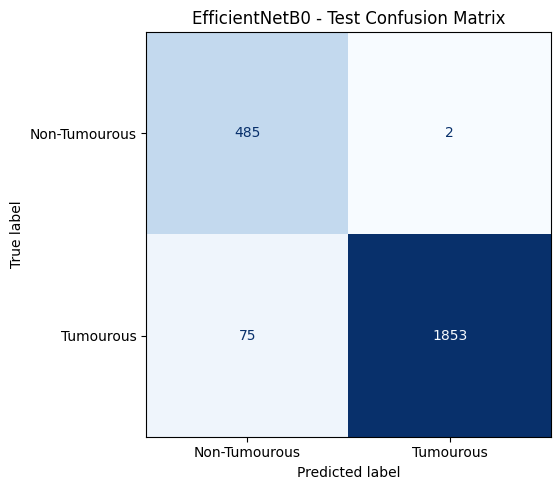

In [21]:
# Plot and save the confusion matrix and test performance metrics.
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Tumourous", "Tumourous"]
).plot(ax=ax, values_format="d", cmap="Blues", colorbar=False)
ax.set_title("EfficientNetB0 - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "efficientnet_confusion_matrix.png"), dpi=300, bbox_inches="tight")
plt.show()

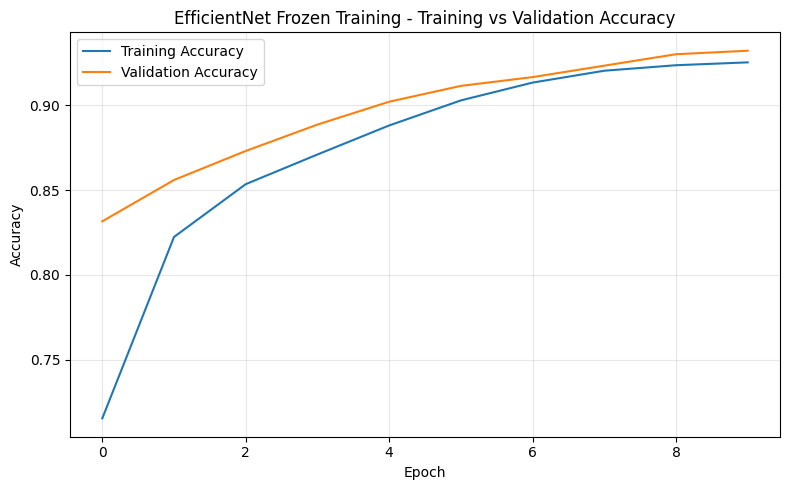

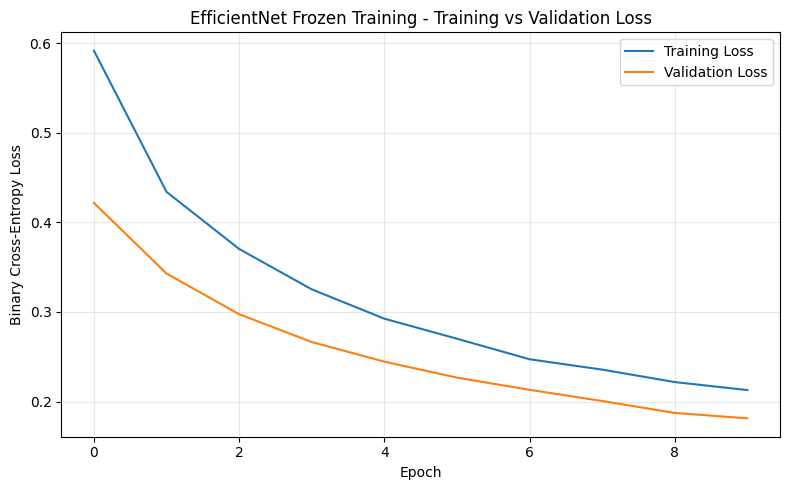

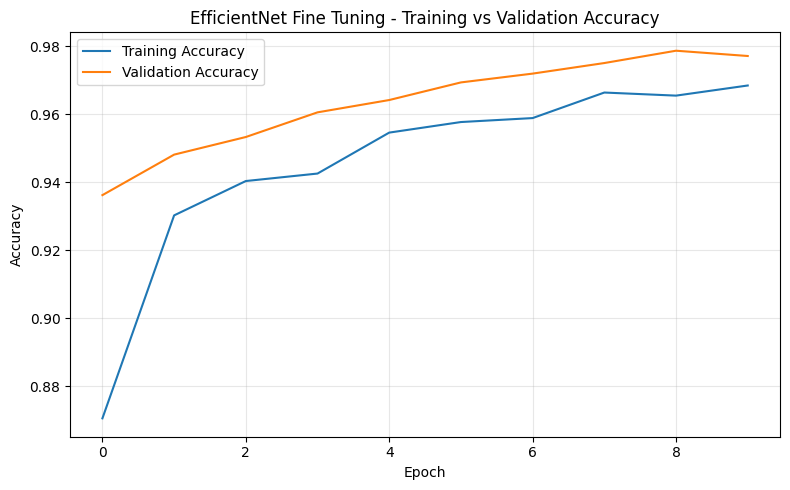

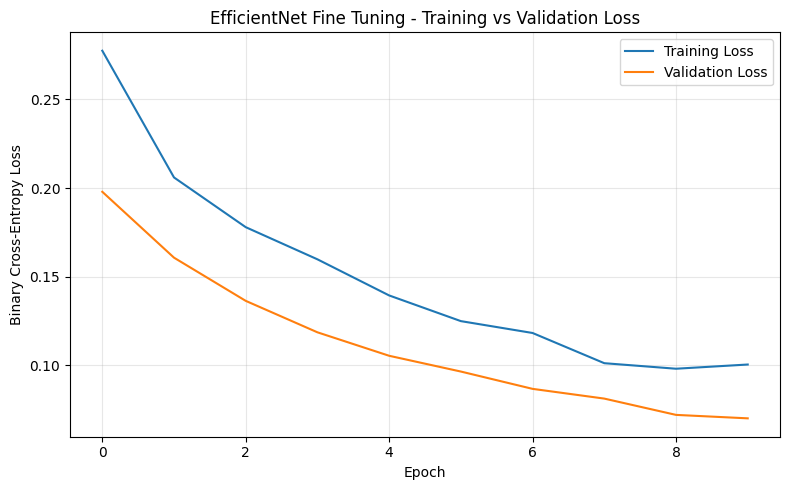

In [22]:
# Plot the frozen-training and fine-tuning learning curves when history is available.
def plot_history(history_obj, prefix):
    if history_obj is None:
        return
    hist = history_obj.history
    if "accuracy" in hist and "val_accuracy" in hist:
        plt.figure(figsize=(8, 5))
        plt.plot(hist["accuracy"], label="Training Accuracy")
        plt.plot(hist["val_accuracy"], label="Validation Accuracy")
        plt.xlabel("Epoch")
        plt.ylabel("Accuracy")
        plt.title(f"{prefix} - Training vs Validation Accuracy")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.savefig(os.path.join(RESULTS_DIR, f"{prefix.lower().replace(' ', '_')}_accuracy.png"), dpi=300)
        plt.show()
    if "loss" in hist and "val_loss" in hist:
        plt.figure(figsize=(8, 5))
        plt.plot(hist["loss"], label="Training Loss")
        plt.plot(hist["val_loss"], label="Validation Loss")
        plt.xlabel("Epoch")
        plt.ylabel("Binary Cross-Entropy Loss")
        plt.title(f"{prefix} - Training vs Validation Loss")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.savefig(os.path.join(RESULTS_DIR, f"{prefix.lower().replace(' ', '_')}_loss.png"), dpi=300)
        plt.show()

plot_history(history_tl, "EfficientNet Frozen Training")
plot_history(history_ft, "EfficientNet Fine Tuning")

In [23]:
# Save predictions and evaluation artifacts to Google Drive for reporting and later comparison.
prediction_results = test_df[["image_path", "original_class", "label"]].copy()
prediction_results = prediction_results.rename(columns={"label": "true_label"})
prediction_results["predicted_probability"] = y_prob
prediction_results["predicted_label"] = y_pred
prediction_results.to_csv(os.path.join(RESULTS_DIR, "efficientnet_test_predictions.csv"), index=False)

metrics_df.to_csv(os.path.join(RESULTS_DIR, "efficientnet_test_metrics.csv"), index=False)
pd.DataFrame(cm, index=["Actual Non-Tumourous", "Actual Tumourous"],
             columns=["Predicted Non-Tumourous", "Predicted Tumourous"]).to_csv(
    os.path.join(RESULTS_DIR, "efficientnet_confusion_matrix.csv")
)
with open(os.path.join(RESULTS_DIR, "efficientnet_classification_report.txt"), "w") as f:
    f.write(report_text)

print("Evaluation artifacts saved to:", RESULTS_DIR)

Evaluation artifacts saved to: /content/drive/MyDrive/Brain_Tumor_CNN_Project/results


In [24]:
# Save the best trained model under a stable final filename for prediction and application use.
FINAL_MODEL_PATH = os.path.join(MODEL_DIR, "efficientnetb0_final.keras")
best_model.save(FINAL_MODEL_PATH)
print("Final EfficientNetB0 model saved to:", FINAL_MODEL_PATH)

Final EfficientNetB0 model saved to: /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/efficientnetb0_final.keras


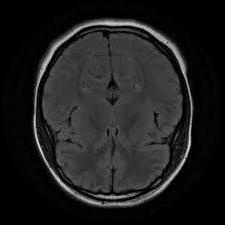

Image: 1519.jpg
Actual label: Non-Tumourous
Predicted label: Non-Tumourous
Tumour probability: 0.0070 (0.70%)


In [25]:
# Display a reproducible sample test image and show its actual label and model prediction.
from IPython.display import display
from PIL import Image

sample_row = test_df.sample(1, random_state=42).iloc[0]
sample_path = sample_row["image_path"]
display(Image.open(sample_path).convert("RGB"))

sample_image = tf.io.read_file(sample_path)
sample_image = tf.io.decode_image(sample_image, channels=3, expand_animations=False)
sample_image.set_shape([None, None, 3])
sample_image = tf.image.resize(sample_image, IMG_SIZE)
sample_image = tf.cast(sample_image, tf.float32)
sample_probability = float(best_model.predict(tf.expand_dims(sample_image, 0), verbose=0)[0][0])

print("Image:", os.path.basename(sample_path))
print("Actual label:", "Tumourous" if int(sample_row["label"]) == 1 else "Non-Tumourous")
print("Predicted label:", "Tumourous" if sample_probability >= 0.5 else "Non-Tumourous")
print("Tumour probability:", f"{sample_probability:.4f} ({sample_probability*100:.2f}%)")